PyTorch wersja: 2.11.0+cu130

Wgraj DWA pliki ZIP (np. warzywa.zip oraz owoce.zip):


Saving warzywa.zip to warzywa (2).zip
Saving owoce.zip to owoce (3).zip

Ścieżka główna danych (ROOT): /content/lab03_data_veggies_fruits/dataset

Wykryte klasy: ['owoce', 'warzywa']
Mapowanie klas na indeksy (class_to_idx): {'owoce': 0, 'warzywa': 1}
Łączna liczba obrazów: 20
Liczność w poszczególnych klasach: {'owoce': 10, 'warzywa': 10}
Nieczytelne obrazy: []

--- STATYSTYKI ZBIORU DANYCH ---
  Klasa  Indeks  Wszystkie  Trening  Walidacja
  owoce       0         10        8          2
warzywa       1         10        8          2

Trening - kształt batcha: (8, 3, 128, 128), typ: torch.float32
Trening - zakres wartości: min = -1.0, max = 1.0
Trening - etykiety w batchu: [0, 0, 0, 1, 0, 1, 1, 0]
Walidacja - kształt batcha: (4, 3, 128, 128), typ: torch.float32
Walidacja - etykiety w batchu: [0, 0, 1, 1]


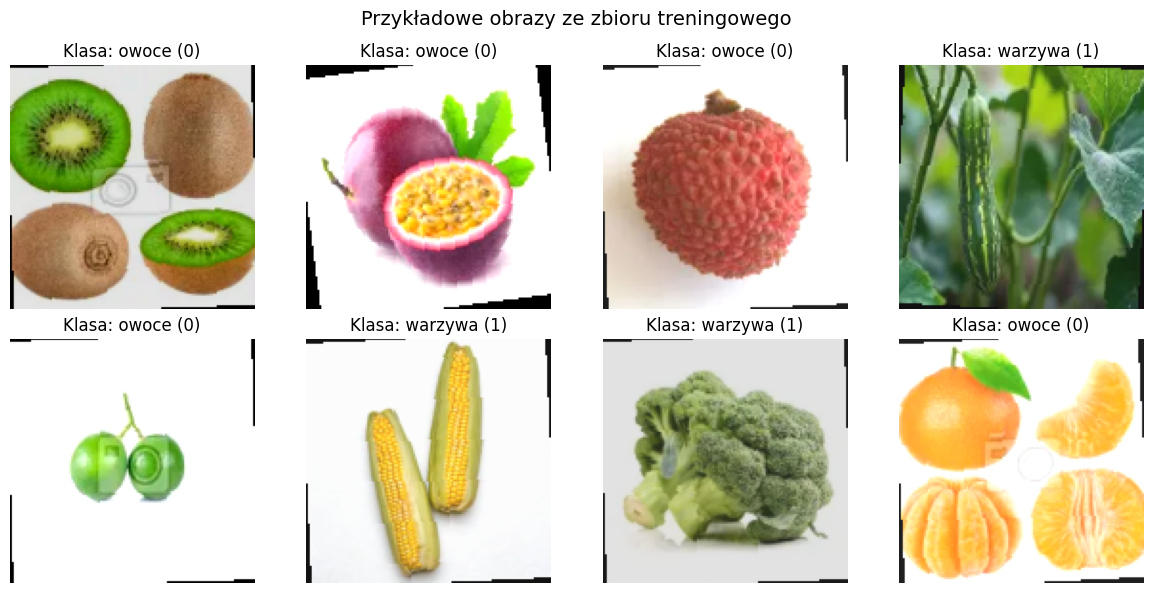

In [17]:

!pip -q install torch torchvision matplotlib pandas pillow pillow-avif-plugin

import os, io, zipfile, shutil, random
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
import pillow_avif
from google.colab import files
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print('PyTorch wersja:', torch.__version__)


print("\nWgraj DWA pliki ZIP (np. warzywa.zip oraz owoce.zip):")
uploaded = files.upload()

base = Path('/content/lab03_data_veggies_fruits')
if base.exists():
    shutil.rmtree(base)
base.mkdir(parents=True)

ROOT = base / "dataset"
ROOT.mkdir(parents=True, exist_ok=True)

for zip_filename, zip_bytes in uploaded.items():
    if not zip_filename.lower().endswith('.zip'):
        continue

    if 'warzyw' in zip_filename.lower():
        target_dir = ROOT / 'warzywa'
    elif 'owoc' in zip_filename.lower():
        target_dir = ROOT / 'owoce'
    else:
        target_dir = ROOT / Path(zip_filename).stem

    target_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
        for item in archive.infolist():
            if not item.is_dir():
                filename = Path(item.filename).name
                if filename:
                    with archive.open(item) as src_file, open(target_dir / filename, "wb") as dst_file:
                        shutil.copyfileobj(src_file, dst_file)

print('\nŚcieżka główna danych (ROOT):', ROOT)


IMG_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.ppm', '.bmp', '.pgm', '.tif', '.tiff', '.webp', '.avif')

ds_raw = datasets.ImageFolder(ROOT, is_valid_file=lambda path: path.lower().endswith(IMG_EXTENSIONS))
print('\nWykryte klasy:', ds_raw.classes)
print('Mapowanie klas na indeksy (class_to_idx):', ds_raw.class_to_idx)
print('Łączna liczba obrazów:', len(ds_raw))
print('Liczność w poszczególnych klasach:', dict(zip(ds_raw.classes, (Counter(ds_raw.targets)[i] for i in range(len(ds_raw.classes))))))

bad = []
for path, label in ds_raw.samples:
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.convert('RGB').load()
    except Exception as e:
        bad.append((path, str(e)))

print('Nieczytelne obrazy:', bad)
assert not bad, "Znaleziono uszkodzone pliki graficzne!"
assert len(ds_raw.classes) == 2, "Liczba klas musi wynosić dokładnie 2!"


indices_train, indices_val = [], []
for cls in range(len(ds_raw.classes)):
    indices = [i for i, target in enumerate(ds_raw.targets) if target == cls]
    rng = np.random.default_rng(42 + cls)
    rng.shuffle(indices)
    cut = int(0.8 * len(indices))
    indices_train.extend(indices[:cut])
    indices_val.extend(indices[cut:])

assert set(indices_train).isdisjoint(indices_val)

mean = [0.5, 0.5, 0.5]
std = [0.5, 0.5, 0.5]

eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_ds = Subset(datasets.ImageFolder(ROOT, transform=train_tf, is_valid_file=lambda path: path.lower().endswith(IMG_EXTENSIONS)), indices_train)
val_ds = Subset(datasets.ImageFolder(ROOT, transform=eval_tf, is_valid_file=lambda path: path.lower().endswith(IMG_EXTENSIONS)), indices_val)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=0)


counts_train = Counter(ds_raw.targets[i] for i in indices_train)
counts_val = Counter(ds_raw.targets[i] for i in indices_val)

stats = pd.DataFrame({
    'Klasa': ds_raw.classes,
    'Indeks': list(range(len(ds_raw.classes))),
    'Wszystkie': [Counter(ds_raw.targets)[i] for i in range(len(ds_raw.classes))],
    'Trening': [counts_train[i] for i in range(len(ds_raw.classes))],
    'Walidacja': [counts_val[i] for i in range(len(ds_raw.classes))]
})

print("\n--- STATYSTYKI ZBIORU DANYCH ---")
print(stats.to_string(index=False))

images_train, labels_train = next(iter(train_loader))
images_val, labels_val = next(iter(val_loader))

print(f'\nTrening - kształt batcha: {tuple(images_train.shape)}, typ: {images_train.dtype}')
print(f'Trening - zakres wartości: min = {images_train.min().item():.1f}, max = {images_train.max().item():.1f}')
print(f'Trening - etykiety w batchu: {labels_train.tolist()}')
print(f'Walidacja - kształt batcha: {tuple(images_val.shape)}, typ: {images_val.dtype}')
print(f'Walidacja - etykiety w batchu: {labels_val.tolist()}')


fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle("Przykładowe obrazy ze zbioru treningowego", fontsize=14)

idx_to_class = {v: k for k, v in ds_raw.class_to_idx.items()}

for i, ax in enumerate(axes.flat):
    if i < len(images_train):
        
        img = images_train[i].numpy().transpose((1, 2, 0))
        img = img * 0.5 + 0.5
        img = np.clip(img, 0, 1)

        label_idx = labels_train[i].item()
        ax.imshow(img)
        ax.set_title(f"Klasa: {idx_to_class[label_idx]} ({label_idx})")
        ax.axis('off')

plt.tight_layout()
plt.show()